# Airbnb 房源数据：描述统计、数据质量评估与价格相关性分析

**香港城市大学 MSc Electronic Commerce · IS6400 课程项目（个人完成） · Notebook 1/4**

基于 Airbnb 公开房源数据，完成变量类型梳理、描述性统计、频数与百分位分析、分组对比；评估数据质量，对比均值/中位数/KNN 三种缺失值插补方法、IQR 与 Z-score 两种异常值检测方法、StandardScaler 与 RobustScaler 两种标准化方法；并通过相关系数与可视化分析各特征与房价（log_price）的关系。

Question 1 – Descriptive Analytics on Airbnb

1.1 Attribute type table：

This table presents comprehensive catagories of variable, including measurement scale, data type, binary type and reasons.

| Variable | Measurement Scale | Reason | Data Type | Reason | Binary Type | Reason |
| --- | --- | --- | --- | --- | --- | --- |
| id | nominal | It has no meaningful order. | discrete | It consists of seperate values. |  |  |
| log_price | ratio | It has meaningful zero. | continuous | It can take decimal values. |  |  |
| property_type | nominal | The categories have no order. | discrete | It contains different types of properties. |  |  |
| accommodates | ratio | It has a meaningful zero and ratios are meaningful. | discrete | The number of guests is counted in whole numbers. |  |  |
| bathrooms | ratio | It has a meaningful zero. | continuous | It can have decimal values, such as 1.5. |  |  |
| bed_type | nominal | The categories have no order. | discrete | It contains different types of beds. |  |  |
| cancellation_policy | nominal | The categories have no order. | discrete | It contains different policy types. |  |  |
| clean_fee | nominal | The categories have no order. | discrete | It shows whether a cleaning fee is charged. | asymmetric | Having a cleaning fee is more meaningful than not having one. |
| city | nominal | The categories have no order. | discrete | It contains different city names. |  |  |
| host_has_profile_pic | nominal | The categories have no order. | discrete | It shows whether the host has a profile picture. | asymmetric | Having a profile picture is usually more important than not having one. |
| host_identity_verified | nominal | The categories have no order. | discrete | It shows whether the host is verified. | asymmetric | Being verified is more meaningful than not being verified. |
| host_response_rate | ratio | Zero means no response, and ratios are meaningful. | continuous | It can take decimal or percentage values. |  |  |
| number_of_reviews | ratio | It has a meaningful zero and ratios are meaningful. | discrete | The number of reviews is counted in whole numbers. |  |  |
| review_scores_rating | ratio | Zero means no rating, and ratios are meaningful. | continuous | It can take decimal values. |  |  |
| bedrooms | ratio | It has a meaningful zero and ratios are meaningful. | discrete | The number of bedrooms is counted in whole numbers. |  |  |
| beds | ratio | It has a meaningful zero and ratios are meaningful. | discrete | The number of beds is counted in whole numbers. |  |  |

1.2 Full descriptive statistics

This section presents a descriptive statistical analysis of the core data categories of Aribnb dataset. The following python codes compute comprehensive statistics, including the mean, median, mode, standard deviation, mininum, maxinum, Q1, Q3, IQR, skewness and kurtosis.

In [1]:
import pandas as pd
import numpy as np
Airbnb = pd.read_csv("../data/Airbnb.csv")

def describe_col(df, col):
    s = df[col].dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)

    return pd.Series({
        'mean': s.mean().round(3),
        'median': s.median().round(3),
        'mode': s.mode().iloc[0].round(3),
        'std': s.std().round(3),
        'min': s.min().round(3),
        'max': s.max().round(3),
        'Q1': q1.round(3),
        'Q3': q3.round(3),
        'IQR': q3-q1,
        'skewness': s.skew().round(3),
        'kurtosis': s.kurt().round(3)
    })

pd.DataFrame({col: describe_col(Airbnb, col) for col in
                ['log_price','accommodates','bathrooms','number_of_reviews','review_scores_rating','bedrooms','beds']}).T

,mean,median,mode,std,min,max,Q1,Q3,IQR,skewness,kurtosis
log_price,4.775,4.7,5.011,0.712,1.609,7.6,4.29,5.193,0.902497,0.526,0.623
accommodates,3.145,2.0,2.000,2.135,1.000,16.0,2.00,4.000,2.000000,2.178,7.065
bathrooms,1.230,1.0,1.000,0.563,0.000,8.0,1.00,1.000,0.000000,3.452,18.480
number_of_reviews,20.830,6.0,0.000,37.493,0.000,532.0,1.00,23.000,22.000000,3.632,19.544
review_scores_rating,94.013,96.0,100.000,7.832,20.000,100.0,92.00,100.000,8.000000,-3.328,19.423
bedrooms,1.272,1.0,1.000,0.855,0.000,10.0,1.00,1.000,0.000000,2.005,7.614
beds,1.704,1.0,1.000,1.233,0.000,18.0,1.00,2.000,1.000000,3.238,18.474


The results offer some clear results of the descriptive statistics. For example, by comparing with the median number and the mean number of log_price, the median log_price is 4.7005, while the mean is 4.7750. This shows that the average price is higher than the median price. The number_of_reviews shows a similar right_skewed pattern, which means they have less abnormal data.

1.3 Frequency and percentage tables

In the section, we compute the frequency and percentage tables of the data using code. Since there are many categorical variables, we store them in a list and using a 'for' loop to caculate each frequency and percentage and build its table.

In [2]:
dataset = [
    'property_type',
    'bed_type',
    'cancellation_policy',
    'cleaning_fee',
    'city',
    'host_has_profile_pic',
    'host_identity_verified'
]

for col in dataset:
    frequency = Airbnb[col].value_counts()
    percentage = Airbnb[col].value_counts(normalize=True).round(4)*100
    table = pd.DataFrame({
        'Frequency': frequency,
        'Percentage': percentage
    })
    print(col)
    display(table)

property_type


,Frequency,Percentage
property_type,,
Apartment,48772,71.58
House,16432,24.12
Townhouse,1690,2.48
Loft,1239,1.82


bed_type


,Frequency,Percentage
bed_type,,
Real Bed,66250,97.24
Futon,687,1.01
Pull-out Sofa,528,0.77
Airbed,433,0.64
Couch,235,0.34


cancellation_policy


...

,Frequency,Percentage
city,,
NYC,31232,45.84
LA,19936,29.26
SF,5542,8.13
DC,5210,7.65
Chicago,3195,4.69
Boston,3018,4.43


host_has_profile_pic


,Frequency,Percentage
host_has_profile_pic,,
t,67745,99.69
f,208,0.31


host_identity_verified


,Frequency,Percentage
host_identity_verified,,
t,45895,67.54
f,22058,32.46


As the presentation of the table, apartment(71.58%) and house(24.12%) together account for 95.70% of all listings, showing that the market is dominated by apartments and houses. And based on the tables,both of 99.69% of the host_has_profile_pic and 67.54% of the host_identity_verified exceed 50%. This suggests that the majority of Airbnb listings in the market have security protection.

1.4 Percentile analysis

In [3]:
percentiles = [0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
pd.DataFrame({
    'log price': Airbnb['log_price'].quantile(percentiles),
    'price': Airbnb['log_price'].apply(np.exp).quantile(percentiles) #还原出price
})

,log price,price
0.25,4.290459,73.0
0.50,4.700480,110.0
0.75,5.192957,180.0
0.90,5.700444,299.0
0.95,6.021023,412.0
0.99,6.856462,950.0


The distribution is right_skewed. As the table shown, from P50 to P99, log_price only increases from 4.70 to 6.85, but the real price jumps from 110 to 950.

1.5 Group comparison

In [4]:
city_stats = Airbnb.groupby('city')['log_price'].agg(['mean', 'median', 'std'])
city_stats['IQR'] = Airbnb.groupby('city')['log_price'].apply(
    lambda x: x.quantile(0.75)-x.quantile(0.25)
)
city_stats

,mean,median,std,IQR
city,,,,
Boston,4.863506,4.867534,0.671552,0.927616
Chicago,4.599758,4.595120,0.688402,0.891631
DC,4.983441,4.828314,0.815965,0.973449
LA,4.726429,4.605170,0.736160,0.916291
NYC,4.712627,4.653960,0.657184,0.916291
SF,5.157632,5.075174,0.681189,0.896488


SF has the highest median log_price at 5.075174, followed by Boston(4.867534) and DC(4.828314), while Chicago is the cheapest(4.595120).

DC has the highest variability based on standard deviation, because DC has the highest standard deviation at 0.815965.

DC also has the highest IQR at 0.973449.

Meanwhile, most cities show right_skewed distributions, where the mean is larger than median, caused by a small number of expensive listings.

In [5]:
property_stats = Airbnb.groupby('property_type')['log_price'].agg(['mean', 'median', 'std'])
property_stats['IQR'] = Airbnb.groupby('property_type')['log_price'].apply(
    lambda x: x.quantile(0.75)-x.quantile(0.25)
)
property_stats

,mean,median,std,IQR
property_type,,,,
Apartment,4.759221,4.744932,0.641154,0.847298
House,4.798188,4.605170,0.876550,1.172720
Loft,5.006105,4.976734,0.745645,0.944749
Townhouse,4.833932,4.691348,0.799160,1.049822


Loft has the highest median log_price at 4.976734, followed by apartment(4.744932) and townhouse(4.691348), while house is the cheapest.

House has highest variability based on standard deviation,because it has the highest standard deviation at 0.876550.

House also has the highest IQR at 1.172720.

Question 2: Data Quality, Visualization, and Relationships with log_price

2.1 Data quality

2.1.1 Missing-value report for all columns

In [6]:
missing = Airbnb.isnull().sum()
missing_ratio = (missing/len(Airbnb)).round(4)
pd.DataFrame({'missing': missing, 'ratio': missing_ratio})[missing > 0]

,missing,ratio
host_has_profile_pic,180,0.0026
host_identity_verified,180,0.0026
review_scores_rating,15275,0.2242


The table summarize the missing value of the dataset. The columns with missing values are both of the host_has_profile_pic and the host_identity_verified with 180 missing values 0.26%, and review_scores_rating with 15275 missing values 22.42%. The overall missing proportion is low, so the data quality is good.

2.1.2 Comparison of mean,median, and KNN

In [7]:
from sklearn.impute import SimpleImputer, KNNImputer

cols = ['review_scores_rating', 'bedrooms']

#Mean
imp_mean = SimpleImputer(strategy = 'mean')
Airbnb[['review_scores_rating_mean', 'bedrooms_mean']] = imp_mean.fit_transform(Airbnb[cols])

#Median
imp_median = SimpleImputer(strategy = 'median')
Airbnb[['review_scores_rating_median', 'bedrooms_median']] = imp_median.fit_transform(Airbnb[cols])

#KNN
imp_knn = KNNImputer(n_neighbors = 5)
knn_vals = imp_knn.fit_transform(Airbnb[cols])
Airbnb['review_scores_rating_knn'] = knn_vals[:,0]
Airbnb['bedrooms_knn'] = knn_vals[:,1]

def summary(col):
    s = Airbnb[col]
    return pd.Series({
        'mean': s.mean(), 'std': s.std(), 'skew': s.skew()
    })

pd.DataFrame({
    'review_original': summary('review_scores_rating'),
    'review_mean': summary('review_scores_rating_mean'),
    'review_median': summary('review_scores_rating_median'),
    'review_knn': summary('review_scores_rating_knn'),
    'bed_original': summary('bedrooms'),
    'bed_mean': summary('bedrooms_mean'),
    'bed_median': summary('bedrooms_median'),
    'bed_knn': summary('bedrooms_knn'),
}).T

,mean,std,skew
review_original,94.012789,7.832125,-3.327538
review_mean,94.012789,6.898510,-3.777841
review_median,94.458309,6.948115,-3.884890
review_knn,94.380791,6.958347,-3.834034
bed_original,1.271733,0.855334,2.005283
bed_mean,1.271733,0.855334,2.005283
bed_median,1.271733,0.855334,2.005283
bed_knn,1.271733,0.855334,2.005283


The table compares the three methods for review_scores_rating and bedrooms.

For review_scores_rating, the methods produced very similar means between 94.012789-94.458309), but mean imputation compresses the standard deviation a lot(from 7.832125 to 6.898510). Because all missing values are filled with the same constant, which reduce teh variance of the distribution. KNN preserves the original distribution best.

Additionally, for bedrooms, all three methods imputation give exactly the same results as the original data, because there is no missing values.

2.1.3 Outlier detection

In [8]:
Airbnb_clean = Airbnb.copy()
Airbnb_clean['review_scores_rating'] = Airbnb_clean['review_scores_rating_knn']
Airbnb_clean['bedrooms'] = Airbnb_clean['bedrooms_knn']
Airbnb_clean[cols].isna().sum()

def iqr_flag(s, k = 1.5):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3-q1
    return (s<q1-k*iqr)|(s>q3+k*iqr)
def z_flag(s, threshold = 3):
    z= (s-s.mean())/s.std()
    return z.abs() > threshold
for col in ['log_price','accommodates','bathrooms']:
    n_iqr = iqr_flag(Airbnb_clean[col]).sum()
    n_z = z_flag(Airbnb_clean[col]).sum()
    print(f"{col}: IQR -> {n_iqr}, Z-score -> {n_z}")

log_price: IQR -> 1453, Z-score -> 453
accommodates: IQR -> 3299, Z-score -> 1378
bathrooms: IQR -> 14307, Z-score -> 1878


The IQR method detects more outliers than Z-score method for all three variables.Z-score assumes an approximately Gaussian variable, so the Z-score method works better when the variable is approximately normally distributed.

Therefore, IQR is more suitable for this Airbnb dataset. Because some variables contain extrem value.

Additional, there are three boxplots of all three variables.

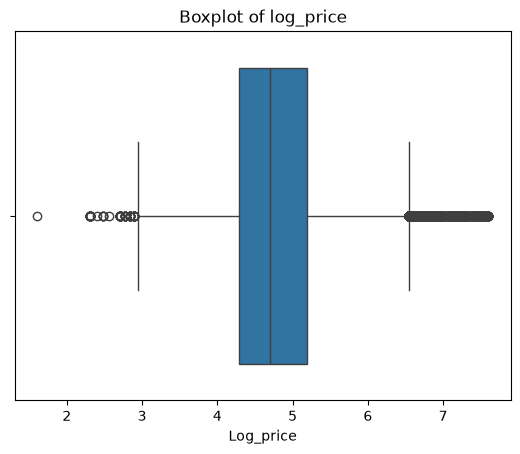

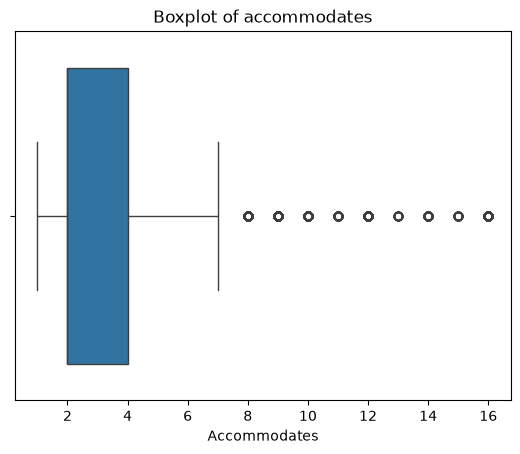

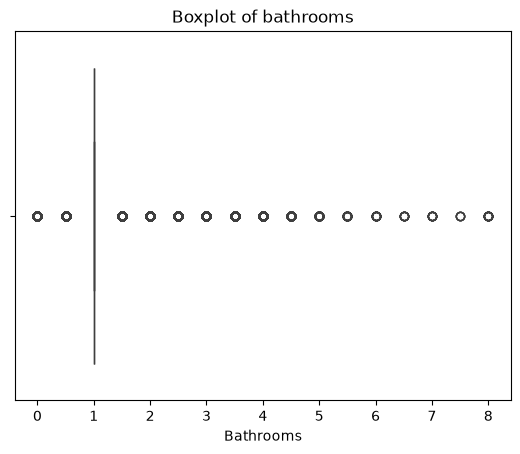

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure()
sns.boxplot(x=Airbnb['log_price'])
plt.title('Boxplot of log_price')
plt.xlabel('Log_price')
plt.show()

plt.figure()
sns.boxplot(x=Airbnb['accommodates'])
plt.title('Boxplot of accommodates')
plt.xlabel('Accommodates')
plt.show()

plt.figure()
sns.boxplot(x=Airbnb['bathrooms'])
plt.title('Boxplot of bathrooms')
plt.xlabel('Bathrooms')
plt.show()

2.1.4 air_clean(KNN)

In [10]:
# 'air_clean' has already been created in Section 2.1.3 and is named 'Airbnb_clean'.
Airbnb_clean['outlier_iqr'] = False
for col in ['log_price','accommodates','bathrooms']:
    Airbnb_clean['outlier_iqr'] = (Airbnb_clean['outlier_iqr'] | iqr_flag(Airbnb_clean[col]))
Airbnb_clean['outlier_iqr'].mean().round(4)

np.float64(0.2249)

2.2 Standardization

In [11]:
from sklearn.preprocessing import StandardScaler, RobustScaler

feats = ['accommodates', 'bathrooms', 'bedrooms', 'beds', 'review_scores_rating','number_of_reviews']
X = Airbnb_clean[feats].copy()
#StandardScaler
X_std = pd.DataFrame(StandardScaler().fit_transform(X), columns=[f + '_std' for f in feats])
#RobustScaler
X_rob = pd.DataFrame(RobustScaler().fit_transform(X), columns=[f + '_rob' for f in feats])

print("StandardScaler:")
print(X_std.describe().T[['mean', 'std', 'min', 'max']])
print()
print("RobustScaler:")
print(X_rob.describe().T[['mean', 'std', 'min', 'max']])

StandardScaler:
                                  mean       std        min        max
accommodates_std          4.223648e-17  1.000007  -1.004790   6.021728
bathrooms_std             2.440330e-17  1.000007  -2.185948  12.029751
bedrooms_std             -4.171504e-17  1.000007  -1.486837  10.204586
beds_std                 -8.207434e-17  1.000007  -1.381144  13.212629
review_scores_rating_std  2.151662e-15  1.000007 -10.689513   0.807555
number_of_reviews_std     3.629209e-17  1.000007  -0.555574  13.633657

RobustScaler:
                              mean       std        min        max
accommodates_rob          0.572498  1.067393  -0.500000   7.000000
bathrooms_rob             0.230160  0.562762  -1.000000   7.000000
bedrooms_rob              0.271733  0.855334  -1.000000   9.000000
beds_rob                  0.703506  1.233412  -1.000000  17.000000
review_scores_rating_rob -0.336535  1.159724 -12.733333   0.600000
number_of_reviews_rob     0.674103  1.704250  -0.272727  23.909091


StandardScaler transforms yhe data using the mean and standard deviation. So it is sensitive to outliers.

RobsterScaler uses the median and IQR. So it is less affected by extreme values.

Comparing with both two methods, use StandardScaler when features are roughly symmetric and outliers are rare.Use RobustScaler when features have outliers or skewed distributions.

2.3 Feature–target relationships

In [12]:
#property_type
Airbnb_clean.groupby('property_type')['log_price'].mean().round(4)

property_type
Apartment    4.7592
House        4.7982
Loft         5.0061
Townhouse    4.8339
Name: log_price, dtype: float64

Text(0, 0.5, 'log_price')

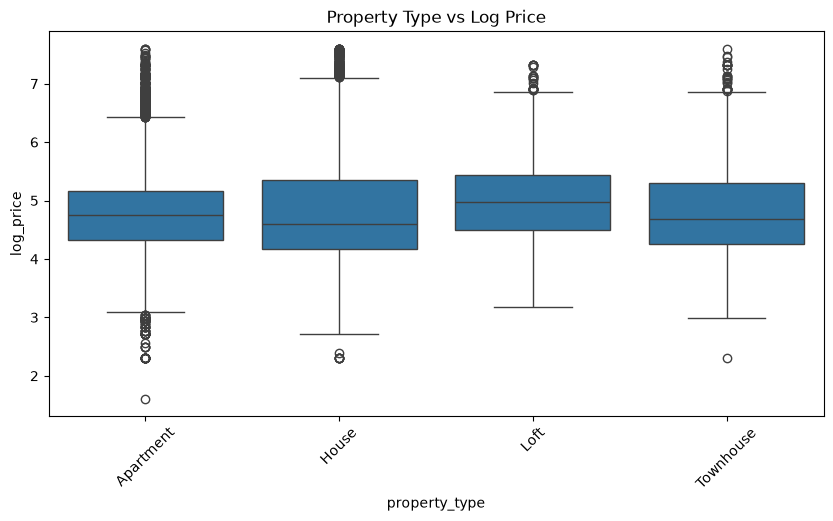

In [13]:
plt.figure(figsize = (10,5))
sns.boxplot(data = Airbnb_clean, x='property_type',y='log_price')
plt.xticks(rotation=45)
plt.title('Property Type vs Log Price')
plt.xlabel('property_type')
plt.ylabel('log_price')

As the boxplot, the mean log_price is different across property_type. Lofts have the highest mean log_price(5.0061), while apartments have the lowest(4.7592). This suggests that property_type may be related to log_price.

In [14]:
#accommodates
Airbnb_clean[['accommodates','log_price']].corr().loc['accommodates','log_price'].round(4)

np.float64(0.5781)

Text(0, 0.5, 'log_price')

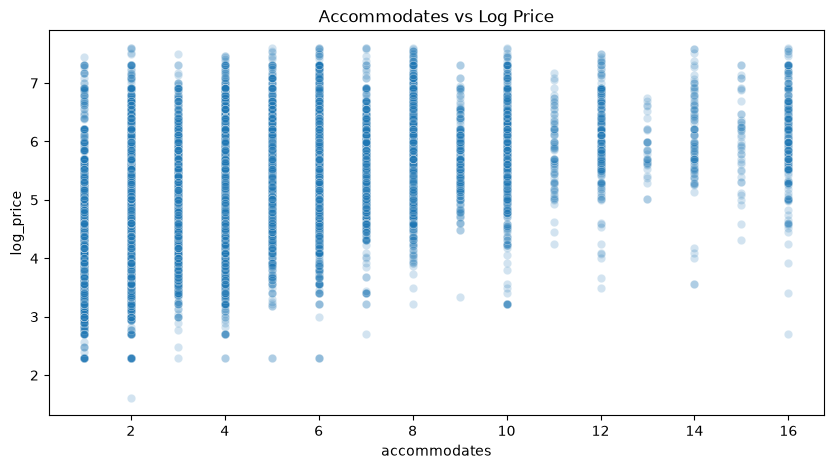

In [15]:
plt.figure(figsize = (10,5))
sns.scatterplot(data=Airbnb_clean, x='accommodates', y='log_price', alpha=0.2)
plt.title('Accommodates vs Log Price')
plt.xlabel('accommodates')
plt.ylabel('log_price')

As the computing, accomodates has a positive correlation with log_price and the correlation is 0.5781. And the scatterplot shows that listings that accomodate more people tend to have a higher 'log_price'. However there is still a considerable gap among listings with similar capicity.

In [16]:
#bathrooms
Airbnb_clean[['bathrooms','log_price']].corr().loc['bathrooms','log_price'].round(4)

np.float64(0.3768)

Text(0, 0.5, 'log_price')

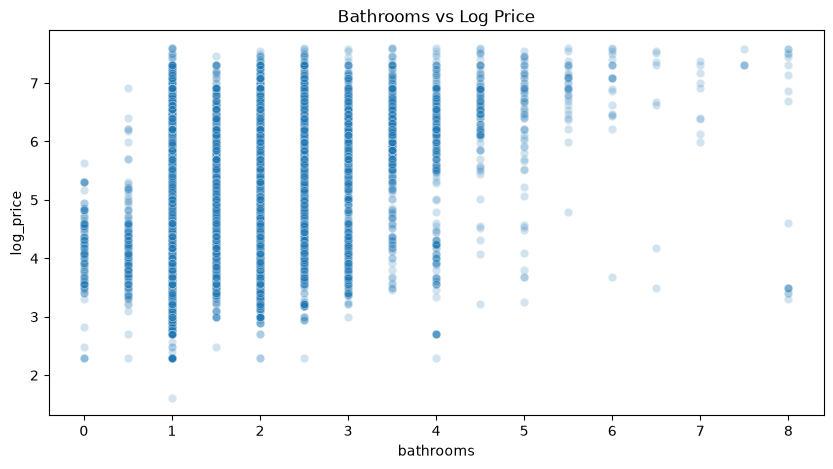

In [17]:
plt.figure(figsize = (10,5))
sns.scatterplot(data=Airbnb_clean, x='bathrooms', y='log_price', alpha=0.2)
plt.title('Bathrooms vs Log Price')
plt.xlabel('bathrooms')
plt.ylabel('log_price')

As the computing, bathrooms has a positive correlation with log_price and the correlation is 0.3768. And the scatterplot shows that listings that more bathrooms tend to have a higher 'log_price'. However the relationship is not as strong as the relationship between accomodates and log_price.

In [18]:
#review_scores_rating
Airbnb_clean[['review_scores_rating','log_price']].corr().loc['review_scores_rating','log_price'].round(4)

np.float64(0.0609)

Text(0, 0.5, 'log_price')

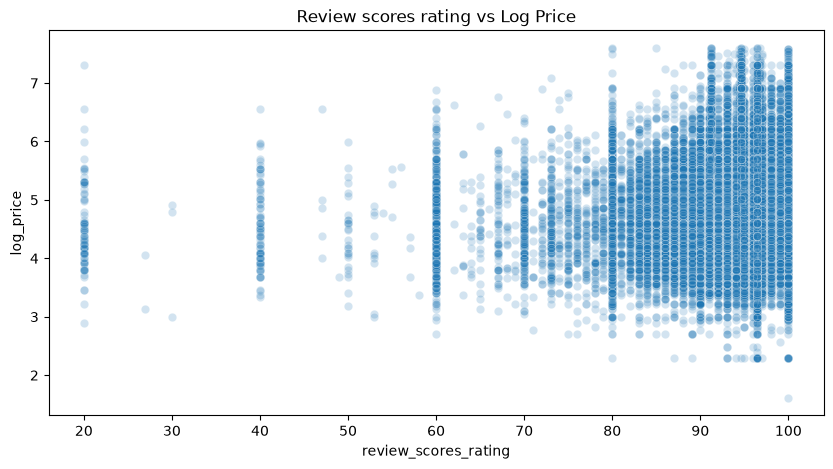

In [19]:
plt.figure(figsize = (10,5))
sns.scatterplot(data=Airbnb_clean, x='review_scores_rating', y='log_price', alpha=0.2)
plt.title('Review scores rating vs Log Price')
plt.xlabel('review_scores_rating')
plt.ylabel('log_price')

As the computing, review_scores_rating has a week positive correlation with log_price and the correlation is 0.0609. And the scatterplot shows that review_scores_rating is not related to log_price.

In [20]:
#bedrooms
Airbnb_clean[['bedrooms','log_price']].corr().loc['bedrooms','log_price'].round(4)

np.float64(0.4827)

Text(0, 0.5, 'log_price')

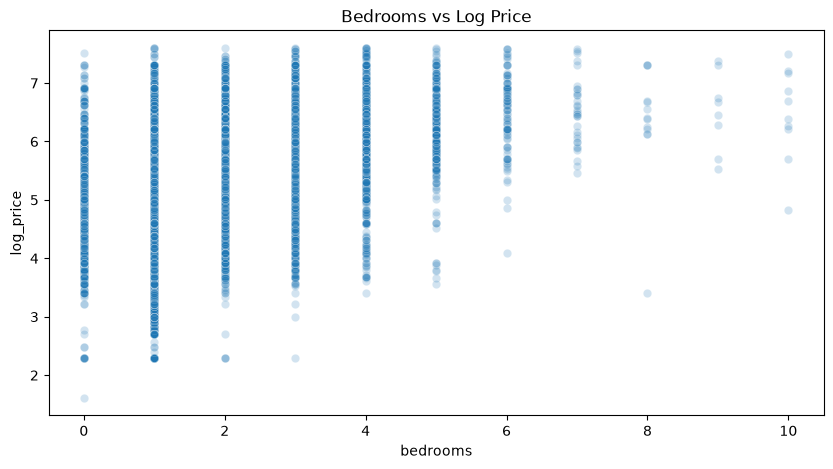

In [21]:
plt.figure(figsize = (10,5))
sns.scatterplot(data=Airbnb_clean, x='bedrooms', y='log_price', alpha=0.2)
plt.title('Bedrooms vs Log Price')
plt.xlabel('bedrooms')
plt.ylabel('log_price')

As the computing, bedrooms has a positive correlation with log_price and the correlation is 0.4827. And the scatterplot shows that listings that more bedrooms tend to have a higher 'log_price'. However there is still a considerable gap among listings with similar capicity.

In [22]:
#beds
Airbnb_clean[['beds','log_price']].corr().loc['beds','log_price'].round(4)

np.float64(0.4697)

Text(0, 0.5, 'log_price')

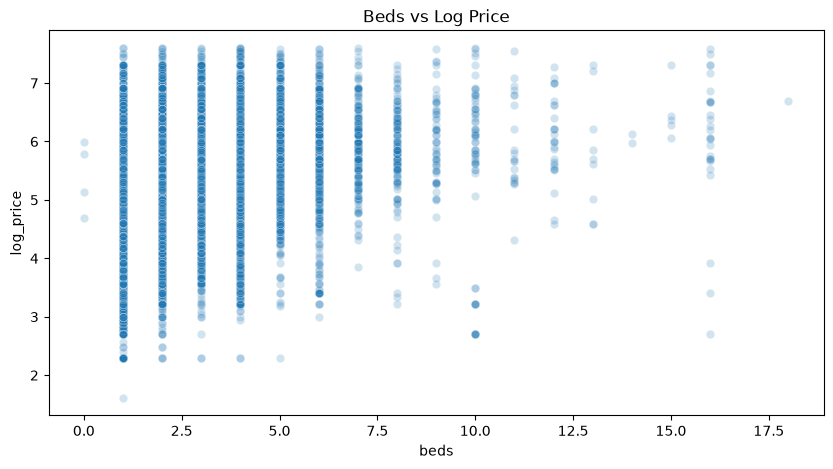

In [23]:
plt.figure(figsize = (10,5))
sns.scatterplot(data=Airbnb_clean, x='beds', y='log_price', alpha=0.2)
plt.title('Beds vs Log Price')
plt.xlabel('beds')
plt.ylabel('log_price')

As the computing, beds has a positive correlation with log_price and the correlation is 0.4697. And the scatterplot shows that listings that more beds tend to have a higher 'log_price'. However there is still a considerable gap among listings with similar capicity.

2.4 Correlation and causation

In [24]:
corr_cols = ['log_price', 'accommodates', 'bathrooms', 'bedrooms', 'beds', 'number_of_reviews', 'review_scores_rating']
corr_matrix = Airbnb_clean[corr_cols].corr()
corr_matrix.round(3)

,log_price,accommodates,bathrooms,bedrooms,beds,number_of_reviews,review_scores_rating
log_price,1.000,0.578,0.377,0.483,0.470,-0.025,0.061
accommodates,0.578,1.000,0.523,0.724,0.829,0.052,-0.040
bathrooms,0.377,0.523,1.000,0.609,0.538,-0.040,-0.000
bedrooms,0.483,0.724,0.609,1.000,0.730,-0.032,-0.001
beds,0.470,0.829,0.538,0.730,1.000,0.038,-0.041
number_of_reviews,-0.025,0.052,-0.040,-0.032,0.038,1.000,-0.020
review_scores_rating,0.061,-0.040,-0.000,-0.001,-0.041,-0.020,1.000


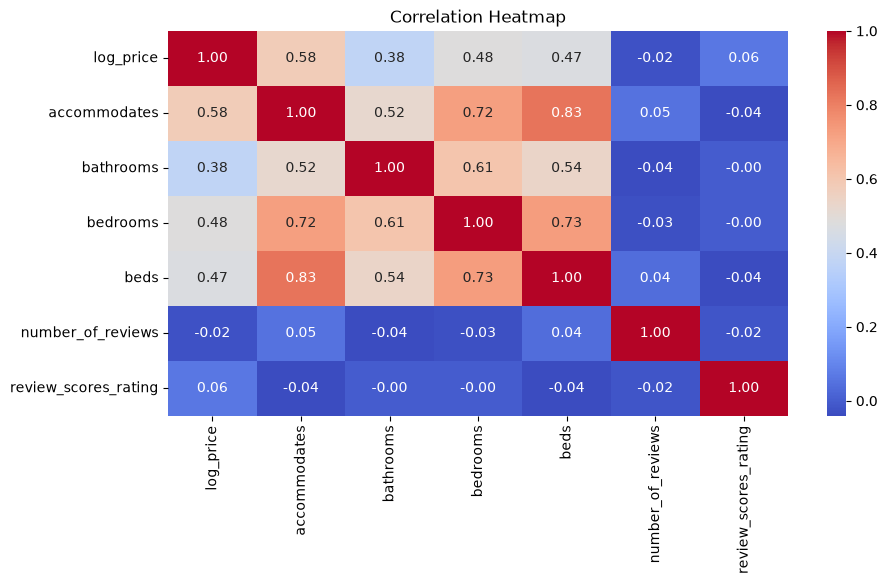

In [25]:
plt.figure(figsize=(10, 5))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

In [26]:
Airbnb_clean[corr_cols].corr()['log_price'].drop('log_price').sort_values(key=abs, ascending=False).head(3)

accommodates    0.578068
bedrooms        0.482682
beds            0.469700
Name: log_price, dtype: float64

Accomodates has the highest correlation with log_price, with a correlation of 0.578068. However, correlation does not imply causation. A larger accommodation capacity does not  nessarity cause a higher price by itself.

Conclusion

The data quality analysis shows that review_scores_rating has a considerable amount of missing data, while bedrooms has no missing values in this dataset.
KNN imputation was selected for review_scores_rating, because the comparison in Section 2.1.2 shows it best preserves the original distribution of the variable.

The IQR method detected more outliers than the Z-score method for log_price, accommodates, and bathrooms.
This suggests that the Airbnb data contain skewness and extreme observations.

The relationship analysis shows that accommodates has the strongest correlation with log_price among the numerical features, with a correlation of 0.5781.
bedrooms and beds also have relatively strong positive co
rrelations of 0.4827 and 0.4697.

Overall, larger properties tend to have higher log_price, but these correlations do not prove causation.
Other factors, such as location, amenities and demand, may also affect Airbnb prices.